# What we learnt uptill now in `Handling missing values`?


* `Part 1`: We learnt CCA(Complete Case Analysis) means remove missing values if it's less than 5% of the total data.
* `Part 2`: Imputation on numeric data
* `Part 3`: Imputation on categorical data

Now in this session, we'll learn below given topics.
* Random imputation
* Missing indicator and
* Automatic select best argument for SimpleImputer()

# Note:
After completing part 4, our topic of Univariate Imputation will be completed and then we'll move to Multivariate imputation.

# Here in this session, we'll study `Random imputation`. 
In random imputation, we fill missing values with any random values from the data. It's not like we impute any value between 1 to 100.
It selects random value from the values present in the data.

**`Note`**: We can't do this using sklearn. We'll hafta use some logic in pandas for performing this.

**`Advantages`**:
* It's easy to apply.
* As we are selectng any random value from the data, distribution(Variance/ Standard deviation) of the data remains almost same.
* It's well suited for **Linear models**.

**`Disadvantages`**:
* We know that we're taking the value from the data, so while deployment also, we'll hafta store the data so that it model can select the value on real time. Hence, it requires more memore while deploying.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("00 titanic.csv", usecols = ['Age', 'Fare', 'Survived'])

In [3]:
df.sample(5)

,Survived,Age,Fare
720,1,6.0,33.0000
42,0,NaN,7.8958
432,1,42.0,26.0000
846,0,NaN,69.5500
624,0,21.0,16.1000


In [4]:
# Total no.of missing values.
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [5]:
# Percentage of missing values.

df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [6]:
# Train test split

from sklearn.model_selection import train_test_split

x = df.iloc[:, 1:3]
y = df.drop(x, axis = 'columns')

In [7]:
x.sample(5)

,Age,Fare
839,NaN,29.7000
841,16.0,10.5000
836,21.0,8.6625
851,74.0,7.7750
750,4.0,23.0000


In [8]:
y.sample(5)

,Survived
278,0
859,0
560,0
715,0
573,1


In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [10]:
x_train.sample(5)

,Age,Fare
16,2.0,29.1250
640,20.0,7.8542
256,NaN,79.2000
688,18.0,7.7958
529,23.0,11.5000


In [11]:
# Fill missing values of x_train{"Age"} with random values
x_train['Age'][x_train['Age'].isnull()] = x_train['Age'].dropna().sample(x_train["Age"].isnull().sum()).values

In [12]:
x_train.Age.isnull().sum()

0

In [13]:
# Fill missing values of x_test["Age"] with random values

x_test['Age'][x_test.Age.isnull()] = x_test['Age'].dropna().sample(x_test['Age'].isnull().sum()).values

In [14]:
x_test.Age.isnull().sum()

0

# Explanation of the code.

* `x_train['Age'][x_train['Age'].isnull()]`: This piece of code returns the series of null values in **Age** column.
* `x_train['Age'].dropna()`: This drops the null values from **Age** column.
* `.sample(x_train["Age"].isnull().sum())`: After dropping null values, we are having only filled values. So this code takes sample from those filled values. **How many samples?** df['Age'].isnull().sum(). This returns the no.of null values in **Age** column, which then passed as an agument to sample(). So sample() returns equal no.of samples as there are null values in the **Age** column.
* `.values`: It converts the result into a numpy array, consisting of only values.
* `.values`: This is required bcz `x_train['Age'][x_train['Age'].isnull()]` returns the pandas series.

# Let's see one more way to fill missing values with random values.

In [15]:
df2 = pd.read_csv("00 titanic.csv", usecols = ['Age', 'Fare', 'Survived'])

In [16]:
df2.tail()

,Survived,Age,Fare
886,0,27.0,13.00
887,1,19.0,30.00
888,0,NaN,23.45
889,1,26.0,30.00
890,0,32.0,7.75


In [17]:
x2, y2 = df.iloc[:, 1:3], df.drop(x, axis = 'columns')

In [18]:
# Train/test split

x_train2, x_test2, y_train2, y_test2 = train_test_split(x2, y2, test_size = 0.2)

In [19]:
x_train2.head()

,Age,Fare
543,32.0,26.0000
328,31.0,20.5250
55,NaN,35.5000
416,34.0,32.5000
709,NaN,15.2458


In [20]:
x_train2.isnull().sum()

Age     139
Fare      0
dtype: int64

In [21]:
# Extracting all the non_missing values in the form of numpy array.(This'll not have any null values)

non_missing_values = x_train2['Age'].dropna().values

non_missing_values[0:20]

array([32., 31., 34., 35., 38., 24., 16., 48., 46., 18., 61., 24., 33.,
       30., 48., 20.,  1., 49., 38., 28.])

In [22]:
# Extracting randon values from non_missing_values.(The no.of values extracted should be equal too the total no.of missing values in the column.)
# This also returns a numpy array.
random_values = np.random.choice(non_missing_values, size = x_train2['Age'].isnull().sum())

random_values

array([35.  , 42.  , 26.  ,  5.  , 39.  , 29.  , 34.  , 17.  ,  0.75,
       17.  , 30.  , 42.  ,  7.  , 26.  , 30.  , 48.  , 48.  , 17.  ,
       44.  , 20.  , 42.  , 19.  , 24.  , 63.  , 28.  , 61.  , 26.  ,
       22.  , 19.  , 42.  , 34.5 , 22.  , 33.  , 43.  , 19.  , 65.  ,
        1.  ,  0.83, 19.  , 48.  , 44.  ,  1.  , 28.  , 34.  , 11.  ,
       17.  , 19.  , 33.  , 56.  , 34.  , 36.  , 28.  , 65.  , 19.  ,
       48.  , 22.  , 36.  , 45.  , 34.  , 51.  , 33.  , 30.  , 61.  ,
       19.  , 21.  , 64.  , 24.  , 32.  , 44.  , 26.  , 60.  , 60.  ,
       30.  , 57.  , 54.  , 65.  , 45.  , 40.  , 36.  , 25.  , 33.  ,
        6.  , 31.  , 60.  , 20.  , 45.  , 17.  , 33.  , 50.  , 18.  ,
       27.  ,  0.83, 21.  , 14.  , 33.  , 31.  , 32.5 , 24.  , 18.  ,
       34.  , 29.  , 30.  , 40.5 , 42.  , 24.  , 34.5 , 43.  , 66.  ,
       37.  , 25.  , 29.  , 30.5 , 60.  , 20.  , 34.  , 56.  , 21.  ,
       33.  , 29.  , 27.  , 19.  , 35.  ,  0.75, 26.  , 19.  , 36.  ,
       16.  , 32.5 ,

In [23]:
print(random_values.size)
print(x_train2['Age'].isnull().sum())

# We can see, the size of null values and random values extracted is same.

139
139


In [24]:
# Filling null values.

x_train2.loc[x_train2['Age'].isnull(), 'Age'] = random_values

In [25]:
x_train2.Age.isnull().sum()

0

# Explanation of the code:


# Starting from the beginning.
Now when we learnt how to impute random values, let's not see, the distributions of the data b4 and after imputation.<br>
For this we'll hafta start from the beginning.

In [26]:
df3 = pd.read_csv("00 titanic.csv", usecols = ['Age', 'Fare', 'Survived'])
df3.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [27]:
df3['Age_imputed'] = df3['Age']

In [28]:
df3.tail()

,Survived,Age,Fare,Age_imputed
886,0,27.0,13.00,27.0
887,1,19.0,30.00,19.0
888,0,NaN,23.45,NaN
889,1,26.0,30.00,26.0
890,0,32.0,7.75,32.0


In [29]:
#Train/ test split.
x3, y3 = df3.iloc[:, 1:4], df3.drop(x, axis = 'columns')
x3.tail()

,Age,Fare,Age_imputed
886,27.0,13.00,27.0
887,19.0,30.00,19.0
888,NaN,23.45,NaN
889,26.0,30.00,26.0
890,32.0,7.75,32.0


In [30]:
x_train3, x_test3, y_train3, y_test3 = train_test_split(x3, y3, test_size = 0.2)

In [31]:
x_train3.head()

,Age,Fare,Age_imputed
519,32.0,7.8958,32.0
238,19.0,10.5000,19.0
446,13.0,19.5000,13.0
650,NaN,7.8958,NaN
349,42.0,8.6625,42.0


In [32]:
x_train3['Age_imputed']

519    32.0
238    19.0
446    13.0
650     NaN
349    42.0
       ... 
694    60.0
434    50.0
614    35.0
315    26.0
351     NaN
Name: Age_imputed, Length: 712, dtype: float64

In [33]:
# Fill missing values of x_train{"Age"} with random values
x_train3['Age_imputed'][x_train3['Age_imputed'].isnull()] = x_train3['Age_imputed'].dropna().sample(x_train3["Age_imputed"].isnull().sum()).values

In [34]:
x_train3.isnull().sum()

# We can see there're zero null value in 'Age_imputed' column.

Age            133
Fare             0
Age_imputed      0
dtype: int64

In [35]:
# Fill missing values of x_test["Age"] with random values

x_test3['Age_imputed'][x_test3.Age.isnull()] = x_test3['Age_imputed'].dropna().sample(x_test3['Age_imputed'].isnull().sum()).values

In [36]:
x_test3.isnull().sum()

Age            44
Fare            0
Age_imputed     0
dtype: int64

In [37]:
# Let's see the distribution of values b4 and after imputation.

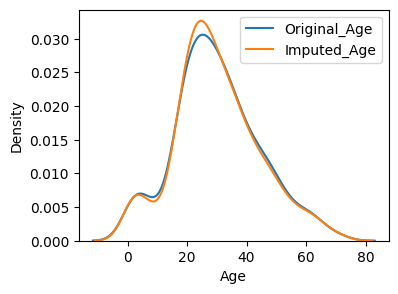

In [38]:
plt.figure(figsize = (4, 3))
sns.kdeplot(x_train3['Age'], label = 'Original_Age')
sns.kdeplot(x_train3['Age_imputed'], label = 'Imputed_Age')
plt.legend()

# We can see that there is very little change in the distribution, bcz we imputed the random values.

In [39]:
# Standard deviation b4 and after imputation

print(f'Original Standard deviation: {x_train3.Age.std()}')
print(f'Std.dev after imutation: {x_train3.Age_imputed.std()}')

Original Standard deviation: 14.358298148529714
Std.dev after imutation: 14.195663603900549


# Next session: Filling missing values with random values, in **Categorical column**.